In [1]:
display("text/html", "<style>.container { width:100% !important; }</style>")

# Let's take a look at the Pigot data

In [2]:
using DataFrames, CSV, Plots, LaTeXStrings, DelimitedFiles, GLM

In [3]:
Plots.theme(:dao)

In [4]:
include("./diversity-simulator.jl")
using .dsim

In [5]:
pal = cgrad(:tol_muted);
cpal10 = [pal[i] for i in 0.0:1/46:1]

In [6]:
length(cpal10)

47

Import the birds. This is one of many.

In [47]:
read_data = CSV.read("./Pigot2025/Pigot2025/EmpiricalData/Birds_Individual.csv", DataFrame)
gd = groupby(read_data, :Site);

In [48]:
gd[1];

In [49]:
cpal20 = [pal[i] for i in 0.0:1/20:1];

In [50]:
si = sortperm(length.([x[!,:N] for x in gd]), rev = true);

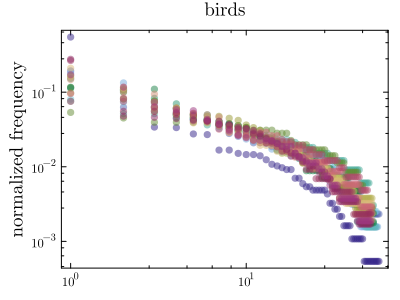

In [51]:
rf_plot1 = scatter(sort(gd[si[1]][!,:N]./sum(gd[si[1]][!,:N]), rev = true), xaxis = :log, yaxis = :log, color = cpal20[1], alpha = 0.5, title = "birds")
for j in 2:minimum([20, length(gd)])
    scatter!(sort(gd[si[j]][!,:N]./sum(gd[si[j]][!,:N]), rev = true), color = cpal20[j], alpha = 0.5)
end
scatter!(legend = :none, size = (400,300), grid = :none, minorgrid = :none, ylabel = "normalized frequency")

Now import the fish.

In [44]:
read_data = CSV.read("./Pigot2025/Pigot2025/EmpiricalData/Fish_Individual.csv", DataFrame)
gd = groupby(read_data, :Site);

In [45]:
si = sortperm(length.([x[!,:N] for x in gd]), rev = true);

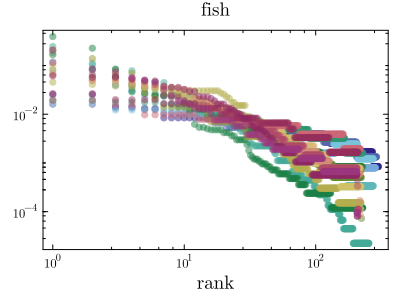

In [46]:
rf_plot2 = scatter(sort(gd[si[1]][!,:N]./sum(gd[si[1]][!,:N]), rev = true), xaxis = :log, yaxis = :log, color = cpal20[1], alpha = 0.5, title = "fish")
for j in 2:minimum([20, length(gd)])
    scatter!(sort(gd[si[j]][!,:N]./sum(gd[si[j]][!,:N]), rev = true), color = cpal20[j], alpha = 0.5)
end
scatter!(legend = :none, size = (400,300), grid = :none, minorgrid = :none, xlabel = "rank")

Now for the mammals.

In [32]:
read_data = CSV.read("./Pigot2025/Pigot2025/EmpiricalData/Mammals_Individual.csv", DataFrame)
gd = groupby(read_data, :Site);

In [33]:
si = sortperm(length.([x[!,:N] for x in gd]), rev = true);

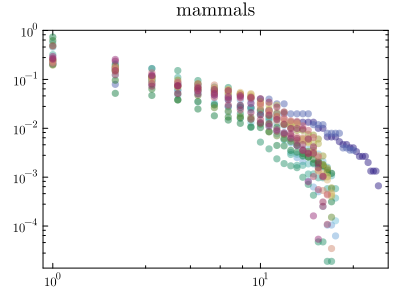

In [43]:
rf_plot3 = scatter(sort(gd[si[1]][!,:N]./sum(gd[si[1]][!,:N]), rev = true), xaxis = :log, yaxis = :log, color = cpal20[1], alpha = 0.5, title = "mammals")
for j in 2:minimum([20, length(gd)])
    scatter!(sort(gd[si[j]][!,:N]./sum(gd[si[j]][!,:N]), rev = true), color = cpal20[j], alpha = 0.5)
end
scatter!(legend = :none, size = (400,300), grid = :none, minorgrid = :none)

In [35]:
using Plots.Measures

In [53]:
plot(rf_plot1,rf_plot2,rf_plot3,layout = (1,3), size = (1000,250), left_margin = 5mm, bottom_margin = 6mm, top_margin = 1mm)
savefig("Pigot-RF-Plot.pdf")

"/home/jamesh/GitHub/Ecological-Preferential-Attachment/Pigot-RF-Plot.pdf"